# Exploratory Data Analysis - Pokec-z

**Projet** : IADATA708 - Responsible AI (Telecom Paris)  
**Dataset** : Pokec-z (sous-ensemble région Zilina du réseau social slovaque Pokec)  
**Objectif** : Comprendre la structure du graphe, les distributions des variables clés (cible, attribut sensible), et identifier les sources potentielles de biais **avant** l'entrainement du GCN.

**Plan** :
1. Chargement des données
2. Vue d'ensemble du graphe
3. Distribution des degrés
4. Distribution de la variable cible (working field)
5. Distribution de l'attribut sensible (genre)
6. Genre par classe cible
7. Homophilie de genre
8. Corrélations features / genre
9. Résumé et implications pour la suite

## 0. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import scipy.sparse as sp
from torch_geometric.data import Data
from torch_geometric.utils import degree
from collections import Counter

# Style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "font.size": 12})

# Reproductibilité
np.random.seed(42)

# Dossier pour sauvegarder les figures
RESULTS_DIR = os.path.join("..", "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

def save_fig(fig, name: str):
    """Sauvegarde une figure dans results/ et l'affiche."""
    fig.savefig(os.path.join(RESULTS_DIR, f"{name}.png"), bbox_inches="tight")
    plt.show()

print("Setup OK")

Setup OK


## 1. Chargement des données Pokec-z

**Source primaire** : [Pokec social network](https://snap.stanford.edu/data/soc-Pokec.html) (SNAP, Stanford) — réseau social slovaque, 1.6M nœuds.  
**Sous-échantillon** : Pokec-z (région Zilina, ~67K nœuds), préprocessé par [Dai & Wang (FairGNN, WSDM 2021)](https://github.com/EnyanDai/FairGNN). Benchmark standard en fairness GNN.

- `region_job.csv` : features des nœuds + label + attribut sensible (région Zilina)
- `region_job_relationship.txt` : liste d'arêtes (paires d'IDs utilisateurs)

In [2]:
import urllib.request, ssl

DATA_DIR = os.path.join("..", "data", "pokec")
os.makedirs(DATA_DIR, exist_ok=True)

BASE_URL = "https://raw.githubusercontent.com/EnyanDai/FairGNN/main/dataset/pokec/"
FILES = ["region_job.csv", "region_job_relationship.txt"]

# Contexte SSL permissif (certains réseaux d'école bloquent la vérification)
ctx = ssl.create_default_context()
ctx.check_hostname = False
ctx.verify_mode = ssl.CERT_NONE

for fname in FILES:
    dest = os.path.join(DATA_DIR, fname)
    if not os.path.exists(dest):
        url = BASE_URL + fname
        print(f"Téléchargement de {fname} ...")
        req = urllib.request.Request(url)
        with urllib.request.urlopen(req, context=ctx) as resp, open(dest, "wb") as f:
            f.write(resp.read())
        print(f"  -> OK ({os.path.getsize(dest) / 1e6:.1f} MB)")
    else:
        print(f"Deja present : {fname} ({os.path.getsize(dest) / 1e6:.1f} MB)")

print("\nFichiers :", os.listdir(DATA_DIR))

Deja present : region_job.csv (38.6 MB)
Deja present : region_job_relationship.txt (11.4 MB)

Fichiers : ['region_job.csv', 'region_job_relationship.txt']


In [3]:
# Inspection rapide du CSV brut
df_raw = pd.read_csv(os.path.join(DATA_DIR, "region_job.csv"))
print(f"Shape : {df_raw.shape}")
print(f"\nColonnes ({len(df_raw.columns)}) :")
print(list(df_raw.columns))
df_raw.head()

Shape : (67796, 279)

Colonnes (279) :
['user_id', 'public', 'completion_percentage', 'gender', 'region', 'AGE', 'I_am_working_in_field', 'spoken_languages_indicator', 'anglicky', 'nemecky', 'rusky', 'francuzsky', 'spanielsky', 'taliansky', 'slovensky', 'japonsky', 'hobbies_indicator', 'priatelia', 'sportovanie', 'pocuvanie hudby', 'pozeranie filmov', 'spanie', 'kupalisko', 'party', 'cestovanie', 'kino', 'diskoteky', 'nakupovanie', 'tancovanie', 'turistika', 'surfovanie po webe', 'praca s pc', 'sex', 'pc hry', 'stanovanie', 'varenie', 'jedlo', 'fotografovanie', 'citanie', 'malovanie', 'chovatelstvo', 'domace prace', 'divadlo', 'prace okolo domu', 'prace v zahrade', 'chodenie do muzei', 'zberatelstvo', 'hackovanie', 'I_most_enjoy_good_food_indicator', 'pri telke', 'v dobrej restauracii', 'pri svieckach s partnerom', 'v posteli', 'v prirode', 'z partnerovho bruska', 'v kuchyni pri stole', 'pets_indicator', 'pes', 'mam psa', 'nemam ziadne', 'macka', 'rybky', 'mam macku', 'mam rybky', 'vta

,user_id,public,completion_percentage,gender,region,AGE,I_am_working_in_field,spoken_languages_indicator,anglicky,nemecky,...,odbornu literaturu,psychologicku literaturu,literaturu pre rozvoj osobnosti,cestopisy,literaturu faktu,poeziu,zivotopisne a pamate,pocitacovu literaturu,filozoficku literaturu,literaturu o umeni a architekture
0,1,1,14,1.0,0,26.0,-1,1,1,0,...,0,0,0,0,0,0,0,0,0,0
1,131075,0,33,1.0,1,25.0,-1,1,0,1,...,0,0,0,0,0,0,0,0,0,0
2,5,1,66,1.0,0,26.0,3,1,1,1,...,0,0,0,0,0,0,0,0,0,0
3,6,0,22,0.0,0,38.0,-1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,7,1,12,0.0,1,22.0,-1,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [4]:
def build_pokec_z_data(data_dir: str,
                       sens_attr: str = "gender",
                       target_attr: str = "I_am_working_in_field") -> Data:
    """Construit un objet PyG Data a partir des fichiers Pokec-z.

    Args:
        data_dir: Chemin vers le dossier contenant les fichiers CSV/TXT.
        sens_attr: Nom de la colonne attribut sensible.
        target_attr: Nom de la colonne cible.

    Returns:
        Data(x, edge_index, y, sens) pret pour l'analyse et le GCN.
    """
    # --- Nœuds ---
    df = pd.read_csv(os.path.join(data_dir, "region_job.csv"))

    # Attribut sensible et cible
    sens = torch.tensor(df[sens_attr].values, dtype=torch.long)
    labels = torch.tensor(df[target_attr].values, dtype=torch.long)

    # Features = toutes les colonnes sauf user_id, sensible et cible
    drop_cols = ["user_id", target_attr]
    feature_cols = [c for c in df.columns if c not in drop_cols]
    x = torch.tensor(df[feature_cols].values, dtype=torch.float32)

    # Remplacer NaN par 0 dans les features
    x = torch.nan_to_num(x, nan=0.0)

    # --- Aretes ---
    edges_df = pd.read_csv(
        os.path.join(data_dir, "region_job_relationship.txt"),
        sep="\t", header=None, names=["src", "dst"]
    )

    # Mapper les user_id vers des indices 0..N-1
    user_ids = df["user_id"].values
    id_to_idx = {uid: i for i, uid in enumerate(user_ids)}

    # Ne garder que les arêtes dont les deux extrémités sont dans le graphe
    mask = edges_df["src"].isin(id_to_idx) & edges_df["dst"].isin(id_to_idx)
    edges_df = edges_df[mask]
    src = torch.tensor([id_to_idx[s] for s in edges_df["src"]], dtype=torch.long)
    dst = torch.tensor([id_to_idx[d] for d in edges_df["dst"]], dtype=torch.long)

    # Graphe non-dirigé : ajouter les arêtes dans les deux sens
    edge_index = torch.stack([
        torch.cat([src, dst]),
        torch.cat([dst, src])
    ], dim=0)

    data = Data(x=x, edge_index=edge_index, y=labels, sens=sens)
    data.feature_names = feature_cols

    print(f"Nœuds : {data.num_nodes:,}")
    print(f"Aretes : {data.num_edges:,} (non-dirigé, comptées 2x)")
    print(f"Features par nœud : {data.x.shape[1]}")
    print(f"Classes cible (y) : {sorted(labels.unique().tolist())}")
    print(f"Valeurs sensible (sens) : {sorted(sens.unique().tolist())}")
    print(f"Feature columns : {feature_cols}")

    return data

data = build_pokec_z_data(DATA_DIR)

Nœuds : 67,796
Aretes : 1,765,530 (non-dirigé, comptées 2x)
Features par nœud : 277
Classes cible (y) : [-1, 0, 1, 2, 3, 4]
Valeurs sensible (sens) : [0, 1]
Feature columns : ['public', 'completion_percentage', 'gender', 'region', 'AGE', 'spoken_languages_indicator', 'anglicky', 'nemecky', 'rusky', 'francuzsky', 'spanielsky', 'taliansky', 'slovensky', 'japonsky', 'hobbies_indicator', 'priatelia', 'sportovanie', 'pocuvanie hudby', 'pozeranie filmov', 'spanie', 'kupalisko', 'party', 'cestovanie', 'kino', 'diskoteky', 'nakupovanie', 'tancovanie', 'turistika', 'surfovanie po webe', 'praca s pc', 'sex', 'pc hry', 'stanovanie', 'varenie', 'jedlo', 'fotografovanie', 'citanie', 'malovanie', 'chovatelstvo', 'domace prace', 'divadlo', 'prace okolo domu', 'prace v zahrade', 'chodenie do muzei', 'zberatelstvo', 'hackovanie', 'I_most_enjoy_good_food_indicator', 'pri telke', 'v dobrej restauracii', 'pri svieckach s partnerom', 'v posteli', 'v prirode', 'z partnerovho bruska', 'v kuchyni pri stole', 

## 2. Vue d'ensemble du graphe

Statistiques globales : taille, densité, degré moyen. Un graphe social est typiquement **sparse** (faible densité) avec une distribution de degrés en **loi de puissance** (quelques hubs tres connectes).

In [5]:
N = data.num_nodes
E = data.num_edges // 2  # arêtes uniques (le graphe est stocké en double)
density = E / (N * (N - 1) / 2)
avg_degree = data.num_edges / N  # chaque arête comptée 2x = somme des degrés

# Nœuds avec label valide (y >= 0)
labeled_mask = data.y >= 0
n_labeled = labeled_mask.sum().item()

print("=" * 50)
print("       VUE D'ENSEMBLE â€” POKEC-Z")
print("=" * 50)
print(f"Nœuds               : {N:>10,}")
print(f"Aretes (uniques)     : {E:>10,}")
print(f"Features / nœud     : {data.x.shape[1]:>10}")
print(f"Densité              : {density:>13.6f}")
print(f"Degré moyen          : {avg_degree:>10.1f}")
print(f"Nœuds avec label    : {n_labeled:>10,} ({100*n_labeled/N:.1f}%)")
print(f"Nœuds sans label    : {N - n_labeled:>10,} ({100*(N-n_labeled)/N:.1f}%)")
print(f"Classes cible        : {sorted(data.y[labeled_mask].unique().tolist())}")
print(f"Attr. sensible       : genre (0/1)")
print("=" * 50)

       VUE D'ENSEMBLE â€” POKEC-Z
Nœuds               :     67,796
Aretes (uniques)     :    882,765
Features / nœud     :        277
Densité              :      0.000384
Degré moyen          :       26.0
Nœuds avec label    :     10,262 (15.1%)
Nœuds sans label    :     57,534 (84.9%)
Classes cible        : [0, 1, 2, 3, 4]
Attr. sensible       : genre (0/1)


## 3. Distribution des degrés

Le degré d'un nœud = son nombre de connexions. Dans un réseau social, on s'attend a une distribution **power-law** : beaucoup de nœuds peu connectes, quelques "hubs" tres connectes. C'est important car le GCN agrege l'information des voisins â€” les nœuds a haut degré melangent plus de signaux.

Degré min   : 1
Degré max   : 597
Degré moyen : 26.0
Degré median: 12
Nœuds isolés (degré 0) : 0


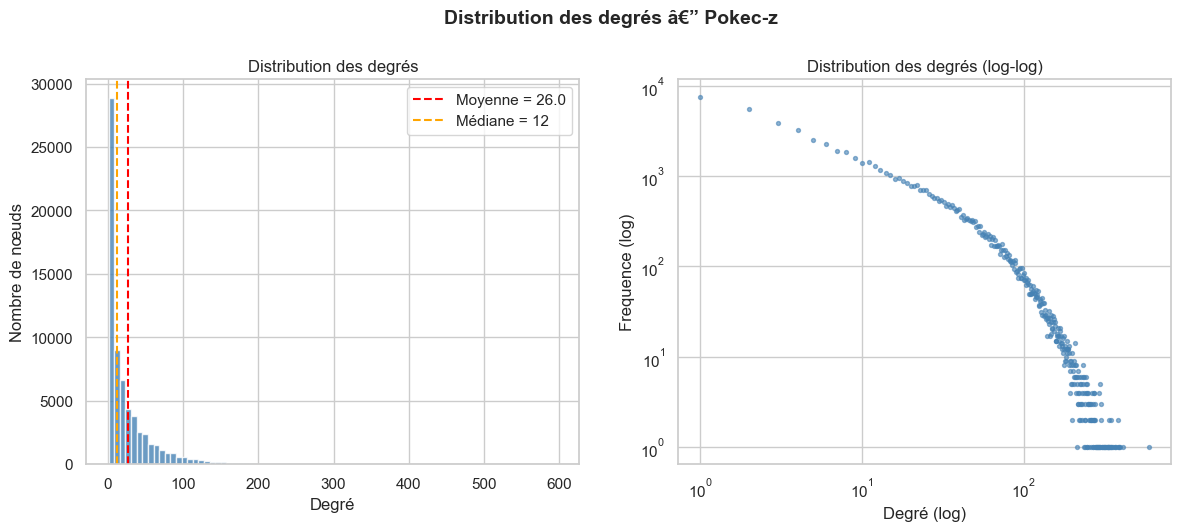

In [6]:
deg = degree(data.edge_index[0], num_nodes=data.num_nodes).numpy()

print(f"Degré min   : {deg.min():.0f}")
print(f"Degré max   : {deg.max():.0f}")
print(f"Degré moyen : {deg.mean():.1f}")
print(f"Degré median: {np.median(deg):.0f}")
print(f"Nœuds isolés (degré 0) : {(deg == 0).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogramme lineaire
axes[0].hist(deg, bins=80, color="steelblue", edgecolor="white", alpha=0.8)
axes[0].set_xlabel("Degré")
axes[0].set_ylabel("Nombre de nœuds")
axes[0].set_title("Distribution des degrés")
axes[0].axvline(np.mean(deg), color="red", ls="--", label=f"Moyenne = {np.mean(deg):.1f}")
axes[0].axvline(np.median(deg), color="orange", ls="--", label=f"Médiane = {np.median(deg):.0f}")
axes[0].legend()

# Histogramme log-log (power-law)
deg_counts = Counter(deg.astype(int))
degs_sorted = sorted(deg_counts.keys())
counts_sorted = [deg_counts[d] for d in degs_sorted]
axes[1].scatter(degs_sorted, counts_sorted, s=8, alpha=0.6, color="steelblue")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Degré (log)")
axes[1].set_ylabel("Frequence (log)")
axes[1].set_title("Distribution des degrés (log-log)")

fig.suptitle("Distribution des degrés â€” Pokec-z", fontsize=14, fontweight="bold", y=1.02)
save_fig(fig, "eda_degree_distribution")

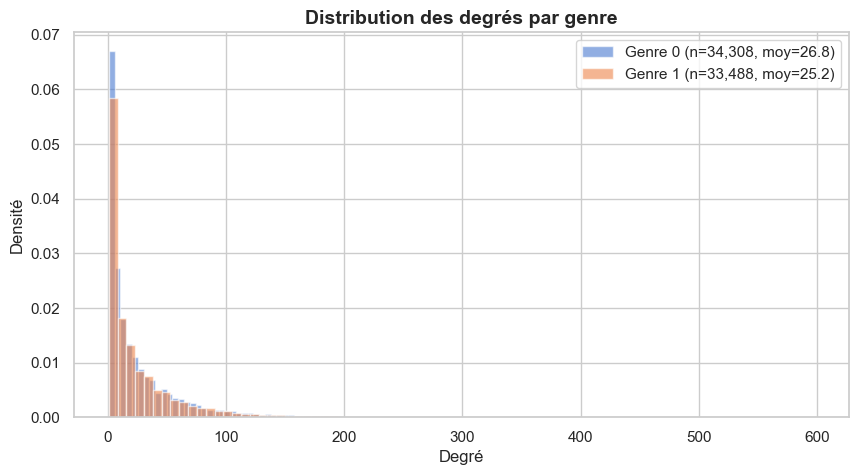

In [7]:
# Degré moyen par genre
deg_g0 = deg[data.sens.numpy() == 0]
deg_g1 = deg[data.sens.numpy() == 1]

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(deg_g0, bins=80, alpha=0.6, label=f"Genre 0 (n={len(deg_g0):,}, moy={deg_g0.mean():.1f})", density=True)
ax.hist(deg_g1, bins=80, alpha=0.6, label=f"Genre 1 (n={len(deg_g1):,}, moy={deg_g1.mean():.1f})", density=True)
ax.set_xlabel("Degré")
ax.set_ylabel("Densité")
ax.set_title("Distribution des degrés par genre", fontsize=14, fontweight="bold")
ax.legend()
save_fig(fig, "eda_degree_by_gender")

## 4. Distribution de la variable cible (working field)

La variable cible est le domaine de travail des utilisateurs. On s'interesse a :
- Le nombre de classes
- L'équilibré entre les classes (deséquilibré = difficulte pour le classifieur)
- Les nœuds sans label (`y < 0`), qui seront exclus de l'evaluation

Labels uniques (y >= 0) : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Nombre de classes       : 5
Nœuds labellisés       : 10,262 / 67,796 (15.1%)

Distribution des classes :
  Classe 0:  4,764 (46.4%)
  Classe 1:  1,964 (19.1%)
  Classe 2:  1,266 (12.3%)
  Classe 3:  1,287 (12.5%)
  Classe 4:    981 (9.6%)

Ratio max/min : 4.9x


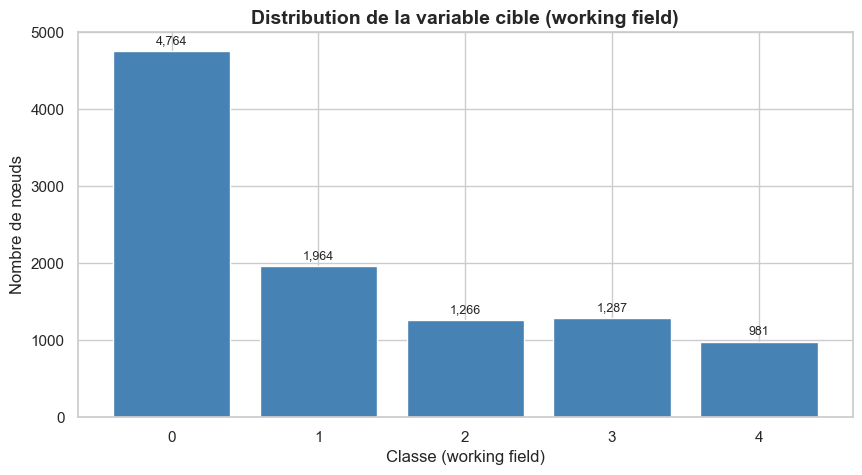

In [8]:
labels = data.y.numpy()
labeled = labels[labels >= 0]

print(f"Labels uniques (y >= 0) : {sorted(np.unique(labeled))}")
print(f"Nombre de classes       : {len(np.unique(labeled))}")
print(f"Nœuds labellisés       : {len(labeled):,} / {len(labels):,} ({100*len(labeled)/len(labels):.1f}%)")

# Distribution des classes
class_counts = pd.Series(labeled).value_counts().sort_index()
print(f"\nDistribution des classes :")
for cls, cnt in class_counts.items():
    print(f"  Classe {cls}: {cnt:>6,} ({100*cnt/len(labeled):.1f}%)")

# Ratio d'imbalance
imbalance_ratio = class_counts.max() / class_counts.min()
print(f"\nRatio max/min : {imbalance_ratio:.1f}x")

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(class_counts.index.astype(str), class_counts.values, color="steelblue", edgecolor="white")
ax.set_xlabel("Classe (working field)")
ax.set_ylabel("Nombre de nœuds")
ax.set_title("Distribution de la variable cible (working field)", fontsize=14, fontweight="bold")

# Annotations
for bar, v in zip(bars, class_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
            f"{v:,}", ha="center", va="bottom", fontsize=9)

save_fig(fig, "eda_class_distribution")

## 5. Distribution de l'attribut sensible (genre)

L'attribut sensible est le genre (binaire : 0 ou 1). Un deséquilibré du genre dans les données peut induire un biais dans le modele, surtout si les **taux de base** (base rates) different entre les groupes â€” c'est-a-dire si la distribution de la cible n'est pas la meme pour les hommes et les femmes.

Répartition du genre :
  Genre 0: 34,308 (50.6%)
  Genre 1: 33,488 (49.4%)


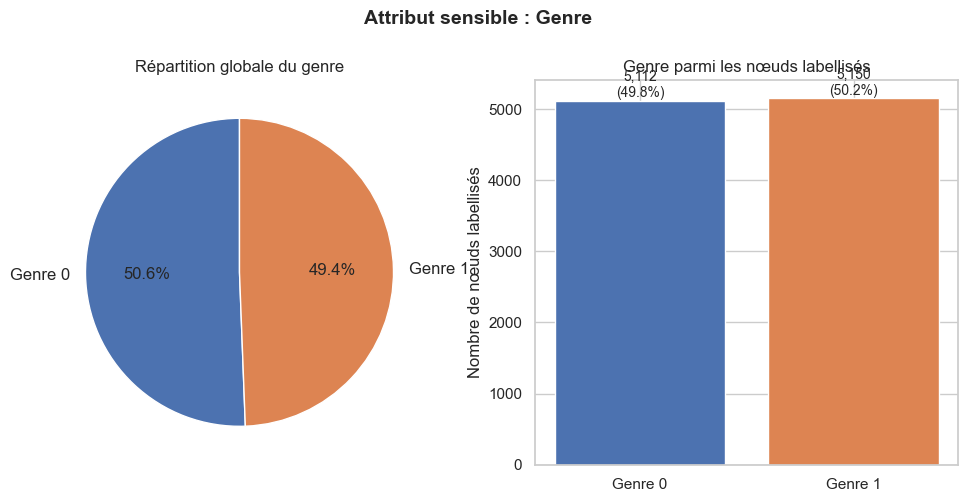

In [9]:
sens = data.sens.numpy()
sens_counts = pd.Series(sens).value_counts().sort_index()

print("Répartition du genre :")
for g, cnt in sens_counts.items():
    print(f"  Genre {g}: {cnt:>6,} ({100*cnt/len(sens):.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Pie chart
colors = ["#4C72B0", "#DD8452"]
axes[0].pie(sens_counts.values, labels=[f"Genre {i}" for i in sens_counts.index],
            autopct="%1.1f%%", colors=colors, startangle=90, textprops={"fontsize": 12})
axes[0].set_title("Répartition globale du genre")

# Bar chart : genre parmi les nœuds labellisés seulement
sens_labeled = sens[labels >= 0]
sens_lab_counts = pd.Series(sens_labeled).value_counts().sort_index()
axes[1].bar([f"Genre {i}" for i in sens_lab_counts.index], sens_lab_counts.values, color=colors, edgecolor="white")
axes[1].set_ylabel("Nombre de nœuds labellisés")
axes[1].set_title("Genre parmi les nœuds labellisés")
for i, (g, v) in enumerate(sens_lab_counts.items()):
    axes[1].text(i, v + 50, f"{v:,}\n({100*v/len(sens_labeled):.1f}%)", ha="center", fontsize=10)

fig.suptitle("Attribut sensible : Genre", fontsize=14, fontweight="bold", y=1.02)
save_fig(fig, "eda_gender_distribution")

## 6. Genre par classe cible (taux de base)

C'est l'analyse la plus importante pour la fairness. Si les taux de base different (P(Y=k|A=0) != P(Y=k|A=1)), alors par le **théorème d'impossibilité de Chouldechova (2017)**, on ne peut pas satisfaire simultanement Demographic Parity et Equalized Odds.

Un écart de taux de base prédit un biais structurel dans le modele.

In [10]:
# Croiser genre et classe cible (nœuds labellisés seulement)
mask_labeled = labels >= 0
df_labeled = pd.DataFrame({
    "genre": sens[mask_labeled],
    "classe": labels[mask_labeled]
})

# Tableau croise
ct = pd.crosstab(df_labeled["classe"], df_labeled["genre"], margins=True)
ct.columns = ["Genre 0", "Genre 1", "Total"]
ct.index = [f"Classe {i}" if i != "All" else "Total" for i in ct.index]
print("Tableau croise Genre x Classe :")
display(ct)

# Proportions par genre (taux de base)
ct_pct = pd.crosstab(df_labeled["classe"], df_labeled["genre"], normalize="columns") * 100
ct_pct.columns = ["Genre 0 (%)", "Genre 1 (%)"]
ct_pct["Ecart (pp)"] = abs(ct_pct["Genre 0 (%)"] - ct_pct["Genre 1 (%)"])
print("\nTaux de base par genre (% au sein de chaque genre) :")
display(ct_pct.round(1))

Tableau croise Genre x Classe :


,Genre 0,Genre 1,Total
Classe 0,2612,2152,4764
Classe 1,1214,750,1964
Classe 2,703,563,1266
Classe 3,536,751,1287
Classe 4,47,934,981
Total,5112,5150,10262



Taux de base par genre (% au sein de chaque genre) :


,Genre 0 (%),Genre 1 (%),Ecart (pp)
classe,,,
0,51.1,41.8,9.3
1,23.7,14.6,9.2
2,13.8,10.9,2.8
3,10.5,14.6,4.1
4,0.9,18.1,17.2


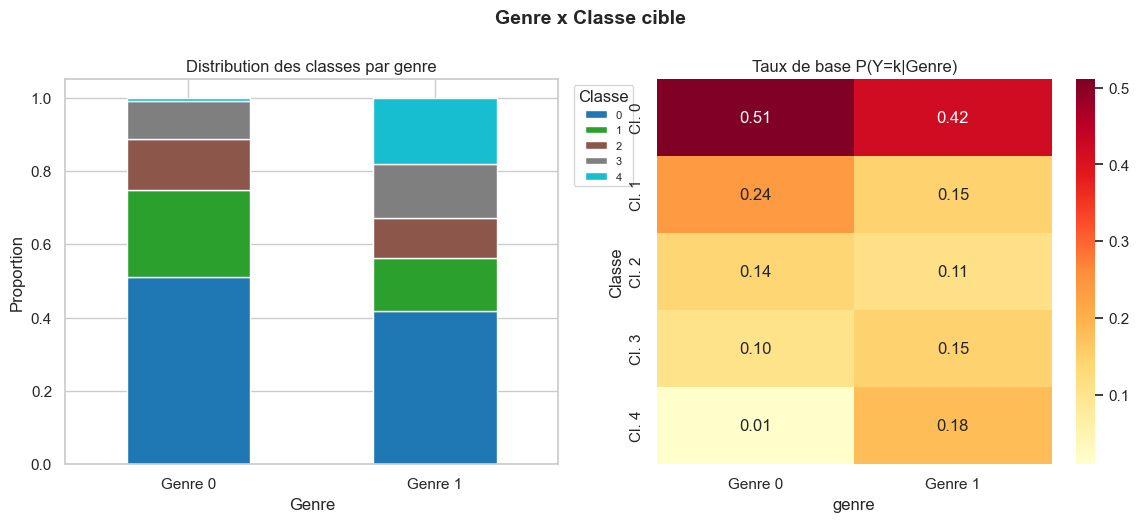

In [11]:
# Stacked bar chart : distribution des classes par genre
ct_norm = pd.crosstab(df_labeled["genre"], df_labeled["classe"], normalize="index")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Stacked bar
ct_norm.plot(kind="bar", stacked=True, ax=axes[0], colormap="tab10", edgecolor="white")
axes[0].set_xlabel("Genre")
axes[0].set_ylabel("Proportion")
axes[0].set_title("Distribution des classes par genre")
axes[0].set_xticklabels(["Genre 0", "Genre 1"], rotation=0)
axes[0].legend(title="Classe", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)

# Heatmap des taux de base
ct_heat = pd.crosstab(df_labeled["classe"], df_labeled["genre"], normalize="columns")
sns.heatmap(ct_heat, annot=True, fmt=".2f", cmap="YlOrRd", ax=axes[1],
            xticklabels=["Genre 0", "Genre 1"],
            yticklabels=[f"Cl. {i}" for i in ct_heat.index])
axes[1].set_title("Taux de base P(Y=k|Genre)")
axes[1].set_ylabel("Classe")

fig.suptitle("Genre x Classe cible", fontsize=14, fontweight="bold", y=1.02)
save_fig(fig, "eda_gender_by_class")

## 7. Homophilie de genre

L'homophilie mesure la tendance des nœuds a se connecter avec des nœuds du **meme groupe**. C'est crucial pour les GNN car :
- Le GCN propage l'information le long des arêtes (message passing)
- Si l'homophilie de genre est forte, le signal "genre" se propage et renforce le biais
- Un ratio > 0.5 = homophilie, = 0.5 = aléatoire, < 0.5 = hétérophilie

       HOMOPHILIE
Genre  : 0.468  (hétérophilie)
Classe : 0.470  (hétérophilie)


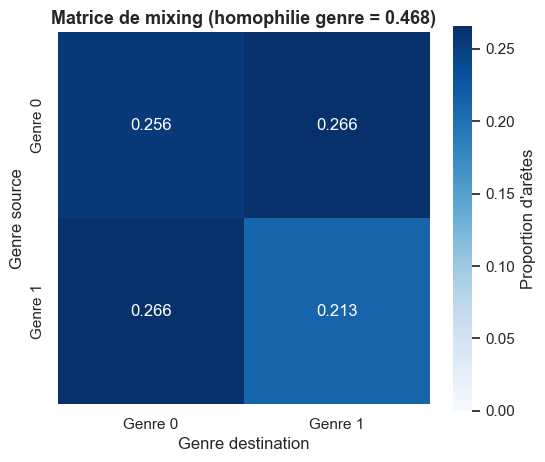

In [12]:
src, dst = data.edge_index[0], data.edge_index[1]
sens_t = data.sens

# Homophilie de genre : fraction d'arêtes intra-genre
same_gender = (sens_t[src] == sens_t[dst]).float()
homo_gender = same_gender.mean().item()

# Homophilie de classe (parmi les nœuds labellisés)
both_labeled = (data.y[src] >= 0) & (data.y[dst] >= 0)
same_class = (data.y[src][both_labeled] == data.y[dst][both_labeled]).float()
homo_class = same_class.mean().item()

print("=" * 45)
print("       HOMOPHILIE")
print("=" * 45)
print(f"Genre  : {homo_gender:.3f}  {'(homophilie)' if homo_gender > 0.5 else '(hétérophilie)' if homo_gender < 0.5 else '(aléatoire)'}")
print(f"Classe : {homo_class:.3f}  {'(homophilie)' if homo_class > 0.5 else '(hétérophilie)' if homo_class < 0.5 else '(aléatoire)'}")
print("=" * 45)

# Detail : matrice de mixing genre
# Compter les arêtes (g_src, g_dst) pour chaque combinaison
edge_types = pd.DataFrame({
    "src_genre": sens_t[src].numpy(),
    "dst_genre": sens_t[dst].numpy()
})
mixing = pd.crosstab(edge_types["src_genre"], edge_types["dst_genre"], normalize="all")
mixing.index = ["Genre 0", "Genre 1"]
mixing.columns = ["Genre 0", "Genre 1"]

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(mixing, annot=True, fmt=".3f", cmap="Blues", ax=ax, square=True,
            vmin=0, cbar_kws={"label": "Proportion d'arêtes"})
ax.set_title(f"Matrice de mixing (homophilie genre = {homo_gender:.3f})",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Genre destination")
ax.set_ylabel("Genre source")
save_fig(fig, "eda_gender_homophily")

## 8. Corrélations features / attribut sensible

On cherche les features les plus corrélées au genre. Ces features sont des **proxies** potentiels : meme si on retirait le genre des features, le modele pourrait reconstruire le genre via ces proxies. C'est ce que l'Acte 2 (XAI) confirmera avec GNNExplainer.

Top 15 features les plus corrélées au genre :


,feature,abs_corr_genre
2,gender,1.000000
78,kratke,0.318497
79,dlhe,0.296398
160,vojnove,0.253113
247,auto-moto sporty,0.231267
95,fialova,0.222702
97,ruzova,0.217884
26,tancovanie,0.216139
25,nakupovanie,0.212057
65,vysportovana,0.210894


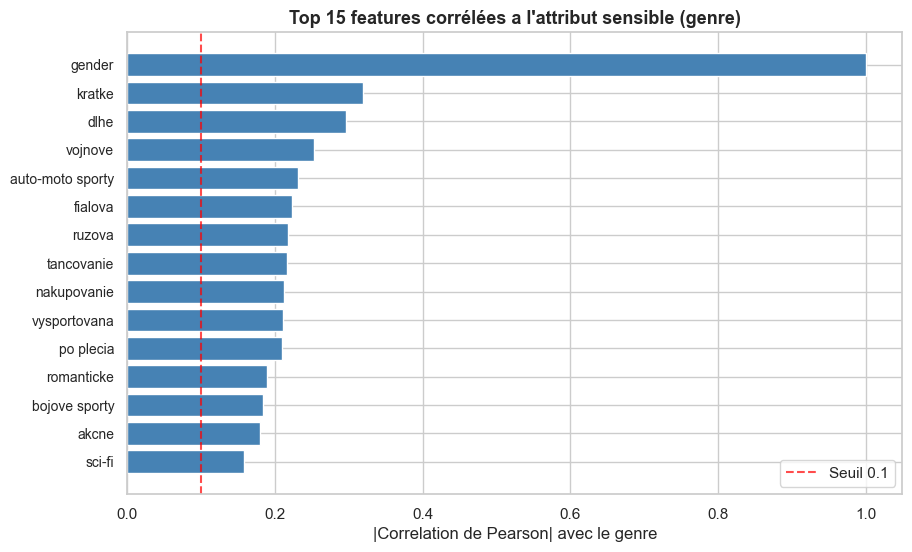

In [13]:
feature_names = data.feature_names
x_np = data.x.numpy()
sens_np = data.sens.numpy().astype(float)

# Correlation de Pearson |corr(feature_i, genre)|
correlations = []
for i in range(x_np.shape[1]):
    # Ignorer les features constantes
    if x_np[:, i].std() == 0:
        correlations.append(0.0)
    else:
        corr = np.corrcoef(x_np[:, i], sens_np)[0, 1]
        correlations.append(abs(corr))

corr_df = pd.DataFrame({
    "feature": feature_names,
    "abs_corr_genre": correlations
}).sort_values("abs_corr_genre", ascending=False)

print("Top 15 features les plus corrélées au genre :")
display(corr_df.head(15))

# Bar plot du top 15
top_k = 15
top = corr_df.head(top_k)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(range(top_k), top["abs_corr_genre"].values, color="steelblue", edgecolor="white")
ax.set_yticks(range(top_k))
ax.set_yticklabels(top["feature"].values, fontsize=10)
ax.set_xlabel("|Correlation de Pearson| avec le genre")
ax.set_title(f"Top {top_k} features corrélées a l'attribut sensible (genre)",
             fontsize=13, fontweight="bold")
ax.invert_yaxis()

# Ligne seuil
ax.axvline(0.1, color="red", ls="--", alpha=0.7, label="Seuil 0.1")
ax.legend()

save_fig(fig, "eda_feature_gender_correlation")

## 9. Statistiques des features

In [14]:
# Statistiques descriptives des features
feat_stats = pd.DataFrame({
    "feature": feature_names,
    "mean": x_np.mean(axis=0),
    "std": x_np.std(axis=0),
    "min": x_np.min(axis=0),
    "max": x_np.max(axis=0),
    "zeros_%": (x_np == 0).mean(axis=0) * 100,
    "nan_%": np.isnan(data.x.numpy()).mean(axis=0) * 100  # avant nan_to_num
})
print(f"Nombre total de features : {len(feature_names)}")
print(f"Features constantes (std=0) : {(feat_stats['std'] == 0).sum()}")
print(f"Features avec >90% de zeros : {(feat_stats['zeros_%'] > 90).sum()}")
print()
display(feat_stats.round(3))

Nombre total de features : 277
Features constantes (std=0) : 0
Features avec >90% de zeros : 144



,feature,mean,std,min,max,zeros_%,nan_%
0,public,0.637000,0.481,0.0,1.0,36.347,0.0
1,completion_percentage,42.264000,24.020,12.0,100.0,0.000,0.0
2,gender,0.494000,0.500,0.0,1.0,50.605,0.0
3,region,0.352000,0.477,0.0,1.0,64.845,0.0
4,AGE,17.177999,13.813,0.0,112.0,30.784,0.0
...,...,...,...,...,...,...,...
272,poeziu,0.025000,0.157,0.0,1.0,97.464,0.0
273,zivotopisne a pamate,0.024000,0.152,0.0,1.0,97.630,0.0
274,pocitacovu literaturu,0.020000,0.139,0.0,1.0,98.029,0.0
275,filozoficku literaturu,0.018000,0.131,0.0,1.0,98.248,0.0


## 10. Composantes connexes

Un rapide aperçu de la connectivité globale du graphe. Un graphe avec une seule grande composante connexe est idéal pour le GCN (le message passing peut atteindre tous les nœuds).

In [15]:
import networkx as nx

# Construire le graphe NetworkX (peut prendre quelques secondes)
print("Construction du graphe NetworkX ...")
edge_list = data.edge_index.t().numpy()
G = nx.Graph()
G.add_nodes_from(range(data.num_nodes))
G.add_edges_from(edge_list)

components = list(nx.connected_components(G))
comp_sizes = sorted([len(c) for c in components], reverse=True)

print(f"\nComposantes connexes : {len(components)}")
print(f"Plus grande composante : {comp_sizes[0]:,} nœuds ({100*comp_sizes[0]/N:.1f}%)")
if len(comp_sizes) > 1:
    print(f"2e plus grande         : {comp_sizes[1]:,} nœuds")
    print(f"Taille des 10 plus grandes : {comp_sizes[:10]}")
print(f"Nœuds isolés          : {sum(1 for s in comp_sizes if s == 1)}")

del G  # liberer la memoire

Construction du graphe NetworkX ...

Composantes connexes : 170
Plus grande composante : 67,435 nœuds (99.5%)
2e plus grande         : 5 nœuds
Taille des 10 plus grandes : [67435, 5, 4, 4, 3, 3, 3, 3, 3, 3]
Nœuds isolés          : 0


## 11. Résumé et implications pour la suite

### Observations clés

| Question | Réponse attendue | Implication |
|----------|-----------------|-------------|
| Le graphe est-il sparse ? | Oui (densité ~10^-4) | Typique d'un réseau social |
| Distribution des degrés ? | Power-law | Quelques hubs influents dans le message passing |
| Les classes sont-elles équilibrées ? | A vérifier | Si deséquilibré, F1-macro > accuracy comme métrique |
| Le genre est-il équilibré ? | A vérifier | Deséquilibré = groupes de taille inegale pour les métriques de fairness |
| Y a-t-il une homophilie de genre ? | A vérifier | Si > 0.5, le GCN propage le biais de genre via la structure |
| Quelles features sont corrélées au genre ? | A vérifier | Proxies a surveiller dans l'Acte 2 (GNNExplainer) |
| Taux de base differents ? | A vérifier | Si oui, impossibilité de Chouldechova â†’ on ne peut pas avoir DP + EOpp |

### Conséquences pour le pipeline

1. **Acte 1 (Baseline)** : Mesurer le biais initial â€” le DP gap sera probablement > 0.05 si les taux de base different
2. **Acte 2 (XAI)** : Vérifier si GNNExplainer identifie le genre et ses proxies parmi les features importantes
3. **Acte 3 (Fairness)** : Le reweighting et la regularisation DP doivent compenser les deséquilibrés identifies ici
4. **Acte 4 (Robustesse)** : Tester si les perturbations d'arêtes affectent differemment les groupes (lie a l'homophilie)

---

*Notebook EDA terminé. Les observations exactes seront complétées apres execution sur les données reelles.*